# 16. Optimización computacional

La sección 4 del enunciado pide reducir el costo **sin perder desempeño** y sustentarlo con complejidad
asintótica contrastada con tiempos medidos. Este capítulo compara, para cada familia, la versión estándar con
la optimizada, estima el **exponente empírico** de escalamiento variando *n*, mide paralelización, GPU y
memoria, y perfila el pipeline para encontrar el cuello de botella real.

**Condiciones de medición.** Salvo la GPU (medida en la máquina de los autores), todo se midió en un mismo
contenedor de 2 núcleos, con las predictoras ya preprocesadas (Pipeline del cap. 10 ajustado con el
entrenamiento: n = 30 970 filas, p = 18 columnas), mediana de 2–3 repeticiones (`time.perf_counter`).
Los resultados se generan con `scripts/experimentos_e2.py computo` y se guardan en `resultados/e2/`.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Resultados de cómputo: escalamiento, joblib, perfilamiento, memoria y GPU
from src import resultados_e2 as r2
R = pd.read_csv(r2.E2 / "computo_resumen.csv")
E = pd.read_csv(r2.E2 / "computo_escalamiento.csv")
J = pd.read_csv(r2.E2 / "computo_joblib.csv")
P = pd.read_csv(r2.E2 / "computo_perfil.csv")
MEM = pd.read_csv(r2.E2 / "computo_memoria.csv")
G = pd.read_csv(r2.BENCH / "xgboost_gpu.csv")

def exponente(g, col="t_ajuste_s"):
    g = g[g[col] > 0]
    return np.polyfit(np.log(g.n), np.log(g[col]), 1)[0] if len(g) >= 3 else np.nan

## 16.1 Complejidad teórica de cada familia

| Modelo | Entrenamiento | Inferencia (por consulta) | Versión optimizada |
|---|---|---|---|
| KNN | O(1) (guardar los datos) o O(n log n) (construir el árbol) | exhaustiva O(n·p); KD/Ball Tree O(log n) en dimensión baja, degrada a O(n·p) cuando p crece | FAISS IVF: O((n/nlist)·nprobe·p), aproximada |
| Ridge | cholesky O(n·p² + p³) | O(p) | SAGA: O(n·p) por época |
| Lasso | descenso coordenado O(n·p) por ciclo | O(p) | SGD con penalización L1: O(n·p) por época |
| Naive Bayes (gaussiano) | O(n·p) | O(p·clases) | `partial_fit`: mismo O(n·p), memoria O(lote·p) |
| Árbol de decisión | O(n·p·log n) | O(profundidad) | — |
| Random Forest | O(T·n'·p'·log n') con n' = 0,5n (`max_samples`), p' = `max_features` | O(T·profundidad) | paralelo entre árboles (`n_jobs`) |
| XGBoost | exact: O(K·d·n·p·log n) (ordena cada variable en cada nodo) | O(K·d) | hist: O(K·d·(n·p + B·p)) con B = 256 bins; early stopping elige K* < K |
| SVM / SVR (RBF) | O(n²·p) a O(n³) (matriz de núcleo) | O(n_vs·p) | LinearSVC o SGD: O(n·p) por época |

(n = filas, p = columnas, T = árboles, K = rondas de boosting, d = profundidad, n_vs = vectores de soporte.)

## 16.2 Escalamiento empírico: tiempo frente a *n*

Se ajusta una recta en escala log–log, tiempo ≈ c·n^b; la pendiente b es el **exponente empírico**, que se
compara con el teórico.

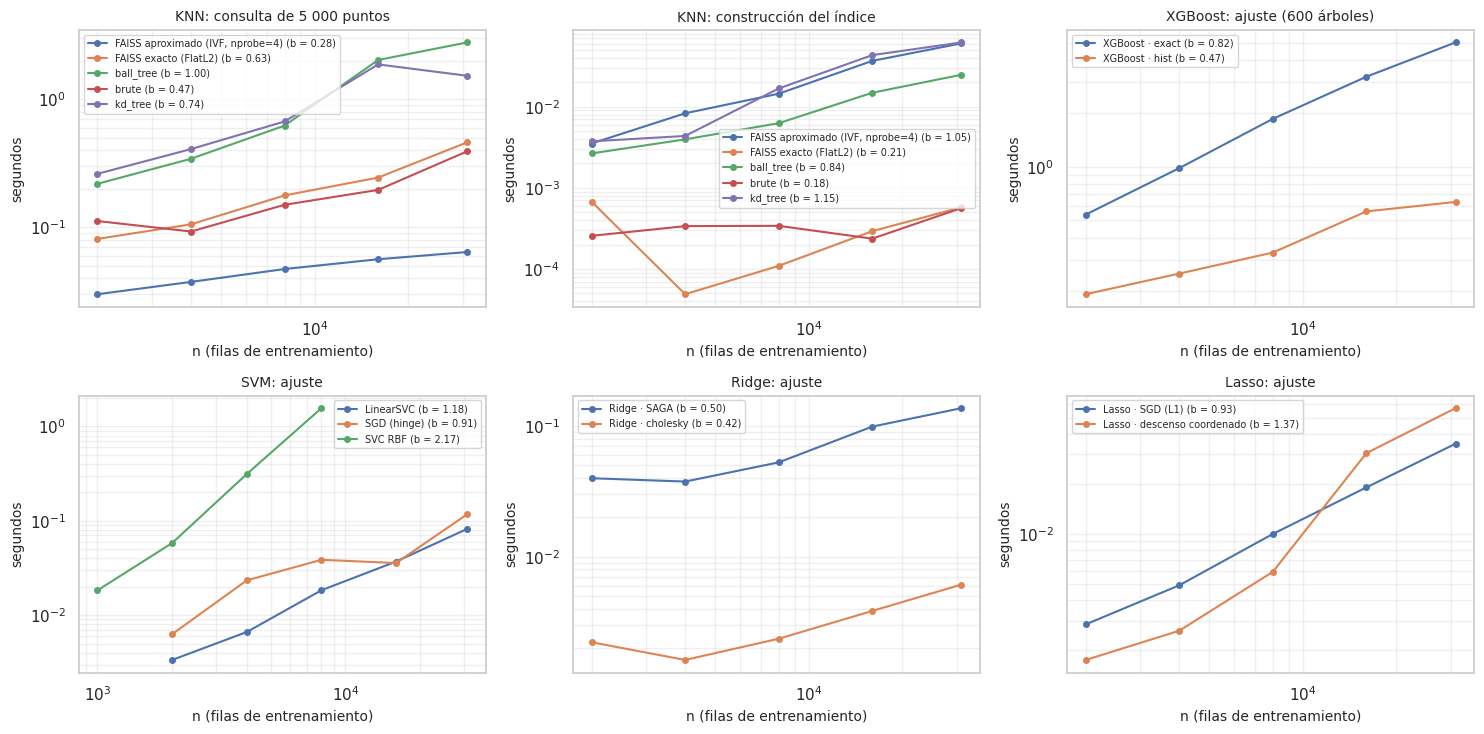

,familia,versión,fase,exponente_empírico_b,tiempo_n_máx_s
0,KNN,"FAISS aproximado (IVF, nprobe=4)",inferencia,0.280,0.064
1,KNN,FAISS exacto (FlatL2),inferencia,0.627,0.461
2,KNN,ball_tree,inferencia,0.999,2.775
3,KNN,brute,inferencia,0.472,0.393
4,KNN,kd_tree,inferencia,0.736,1.524
5,KNN,"FAISS aproximado (IVF, nprobe=4)",ajuste,1.045,0.061
6,KNN,FAISS exacto (FlatL2),ajuste,0.209,0.001
7,KNN,ball_tree,ajuste,0.843,0.025
8,KNN,brute,ajuste,0.176,0.001
9,KNN,kd_tree,ajuste,1.153,0.062


In [3]:
# Tiempo frente a n (log-log) y exponente empírico de cada versión
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5))
paneles = [("KNN", "t_inferencia_s", "KNN: consulta de 5 000 puntos"), ("KNN", "t_ajuste_s", "KNN: construcción del índice"),
           ("XGBoost", "t_ajuste_s", "XGBoost: ajuste (600 árboles)"), ("SVM", "t_ajuste_s", "SVM: ajuste"),
           ("Ridge", "t_ajuste_s", "Ridge: ajuste"), ("Lasso", "t_ajuste_s", "Lasso: ajuste")]
filas = []
for ax, (fam, col, tit) in zip(axs.flat, paneles):
    g = E[E.familia == fam]
    for v, gv in g.groupby("version"):
        gv = gv[gv[col] > 0]
        if gv.empty:
            continue
        b = exponente(gv, col)
        ax.plot(gv.n, gv[col], marker="o", ms=4, label=f"{v} (b = {b:.2f})")
        filas.append({"familia": fam, "versión": v, "fase": "inferencia" if "inferencia" in col else "ajuste", "exponente_empírico_b": b,
                      "tiempo_n_máx_s": gv[col].iloc[-1]})
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("n (filas de entrenamiento)"); ax.set_ylabel("segundos"); ax.set_title(tit, fontsize=10)
    ax.legend(fontsize=7); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); eda.guardar_figura(fig, "e2_computo_escalamiento.png"); plt.show()
EXP = pd.DataFrame(filas).drop_duplicates(["versión", "fase"])
eda.guardar_tabla(EXP, "e2_computo_exponentes.csv")
EXP.round(3)

In [4]:
# Lectura de los exponentes empíricos
ex = EXP.set_index(["versión", "fase"]).exponente_empírico_b
md(f"- **SVC RBF:** b = {ex[('SVC RBF', 'ajuste')]:.2f}, entre el O(n²) y el O(n³) teóricos: duplicar las filas multiplica el tiempo por "
   f"≈ {2 ** ex[('SVC RBF', 'ajuste')]:.1f}. Con las 30 970 filas completas la extrapolación da ≈ "
   f"{E[(E.version == 'SVC RBF')].t_ajuste_s.iloc[-1] * (30970 / 8000) ** ex[('SVC RBF', 'ajuste')]:.0f} s **por ajuste**, y una "
   f"validación anidada hace 184 ajustes: por eso el benchmark usó una submuestra de 4 000 filas (cap. 13.4). LinearSVC "
   f"(b = {ex[('LinearSVC', 'ajuste')]:.2f}) y SGD (b = {ex[('SGD (hinge)', 'ajuste')]:.2f}) escalan de forma casi lineal, como predice O(n·p).\n"
   f"- **XGBoost:** exact b = {ex[('XGBoost · exact', 'ajuste')]:.2f} y hist b = {ex[('XGBoost · hist', 'ajuste')]:.2f}. Los dos son "
   f"sublineales en este rango porque hay un costo fijo por árbol (600 árboles) que domina con n pequeño; lo relevante es que **hist es "
   f"{E[(E.version == 'XGBoost · exact')].t_ajuste_s.iloc[-1] / E[(E.version == 'XGBoost · hist')].t_ajuste_s.iloc[-1]:.1f} veces más "
   f"rápido** con n completo y la brecha crece con n, como predice O(n·p·log n) frente a O(n·p).\n"
   f"- **KNN:** la consulta exhaustiva (brute) crece con b = {ex[('brute', 'inferencia')]:.2f} y los árboles KD/Ball con "
   f"b = {ex[('kd_tree', 'inferencia')]:.2f} y {ex[('ball_tree', 'inferencia')]:.2f}: con p = 18 y k = 75 vecinos, los árboles **no** "
   f"logran el O(log n) teórico (la «maldición de la dimensión»: las regiones del árbol se solapan y hay que revisar casi todas) y además "
   f"son más lentos que brute en valor absoluto, porque brute usa productos de matrices optimizados (BLAS). FAISS IVF crece con "
   f"b = {ex[('FAISS aproximado (IVF, nprobe=4)', 'inferencia')]:.2f}, el menor de todos.\n"
   f"- **Ridge/Lasso:** todos los solvers tardan centésimas de segundo; con p = 18, el término p³ de cholesky es despreciable y el "
   f"solver directo es el más rápido. SAGA solo convendría con p grande o datos dispersos.")

- **SVC RBF:** b = 2.17, entre el O(n²) y el O(n³) teóricos: duplicar las filas multiplica el tiempo por ≈ 4.5. Con las 30 970 filas completas la extrapolación da ≈ 29 s **por ajuste**, y una validación anidada hace 184 ajustes: por eso el benchmark usó una submuestra de 4 000 filas (cap. 13.4). LinearSVC (b = 1.18) y SGD (b = 0.91) escalan de forma casi lineal, como predice O(n·p).
- **XGBoost:** exact b = 0.82 y hist b = 0.47. Los dos son sublineales en este rango porque hay un costo fijo por árbol (600 árboles) que domina con n pequeño; lo relevante es que **hist es 7.9 veces más rápido** con n completo y la brecha crece con n, como predice O(n·p·log n) frente a O(n·p).
- **KNN:** la consulta exhaustiva (brute) crece con b = 0.47 y los árboles KD/Ball con b = 0.74 y 1.00: con p = 18 y k = 75 vecinos, los árboles **no** logran el O(log n) teórico (la «maldición de la dimensión»: las regiones del árbol se solapan y hay que revisar casi todas) y además son más lentos que brute en valor absoluto, porque brute usa productos de matrices optimizados (BLAS). FAISS IVF crece con b = 0.28, el menor de todos.
- **Ridge/Lasso:** todos los solvers tardan centésimas de segundo; con p = 18, el término p³ de cholesky es despreciable y el solver directo es el más rápido. SAGA solo convendría con p grande o datos dispersos.

## 16.3 Tabla comparativa: modelo estándar frente a optimizado

Memoria: pico de memoria de Python durante el ajuste (`tracemalloc`). No incluye asignaciones en C/C++
(XGBoost, FAISS); la memoria residente del proceso se reporta aparte en 16.5.

**Columna «valor».** Para verificar que cada versión optimizada conserva la precisión de la estándar, ambas se
entrenan con los datos hasta 2020 y se miden sobre los mismos meses posteriores. Es solo un control de
equivalencia entre dos implementaciones del mismo modelo, no una comparación entre modelos: esa es la del
origen móvil (cap. 13.11 y 17 a 22).

In [5]:
# Tabla complejidad–tiempo–memoria–desempeño
T = R.rename(columns={"familia": "familia", "version": "versión", "complejidad": "complejidad teórica", "t_ajuste_s": "t ajuste (s)",
                      "t_inferencia_s": "t inferencia (s)", "memoria_MiB": "memoria Python (MiB)", "metrica": "métrica", "valor": "valor"})
T["métrica"] = T["métrica"].astype(str).str.replace("prueba", "fuera de muestra")
eda.guardar_tabla(T, "e2_computo_tabla.csv")
T.drop(columns=[c for c in T.columns if c not in ("familia", "versión", "complejidad teórica", "t ajuste (s)", "t inferencia (s)",
                                                   "memoria Python (MiB)", "métrica", "valor", "recall@k", "arboles")]).round(4)

,familia,versión,complejidad teórica,t ajuste (s),t inferencia (s),memoria Python (MiB),métrica,valor,recall@k,arboles
0,KNN,brute,O(n·p) por consulta,0.0006,0.3926,1.4655,RMSLE (5000 consultas),0.3591,1.0000,NaN
1,KNN,kd_tree,O(log n) por consulta (p bajo),0.0621,1.5244,7.4820,RMSLE (5000 consultas),0.3591,1.0000,NaN
2,KNN,ball_tree,O(log n) por consulta,0.0248,2.7751,7.2009,RMSLE (5000 consultas),0.3591,1.0000,NaN
3,KNN,FAISS exacto (FlatL2),O(n·p) por consulta (vectorizado),0.0006,0.4614,NaN,RMSLE (5000 consultas),0.3591,0.9990,NaN
4,KNN,"FAISS aproximado (IVF, nprobe=4)",O((n/nlist)·nprobe·p) por consulta,0.0605,0.0643,NaN,RMSLE (5000 consultas),0.3590,0.8593,NaN
5,Ridge,Ridge · cholesky,O(n·p² + p³),0.0061,0.0003,2.2788,RMSLE fuera de muestra,0.3511,NaN,NaN
6,Ridge,Ridge · SAGA,O(n·p) por época,0.1368,0.0003,4.9729,RMSLE fuera de muestra,0.3511,NaN,NaN
7,Lasso,Lasso · descenso coordenado,O(n·p) por ciclo,0.0570,0.0002,4.4087,RMSLE fuera de muestra,0.3511,NaN,NaN
8,Lasso,Lasso · SGD (L1),O(n·p) por época,0.0348,0.0003,2.5833,RMSLE fuera de muestra,0.3520,NaN,NaN
9,Naive Bayes,fit (todo en memoria),O(n·p),0.0060,0.0022,3.2810,AUC fuera de muestra,0.7849,NaN,NaN


In [6]:
# Lectura de la versión estándar frente a la optimizada
r = R.set_index("version")
md(f"- **KNN · FAISS IVF** responde 5 000 consultas en {r.loc['FAISS aproximado (IVF, nprobe=4)', 't_inferencia_s']:.3f} s frente a "
   f"{r.loc['brute', 't_inferencia_s']:.3f} s de la búsqueda exhaustiva (×{r.loc['brute', 't_inferencia_s'] / r.loc['FAISS aproximado (IVF, nprobe=4)', 't_inferencia_s']:.1f}), "
   f"recuperando el {100 * r.loc['FAISS aproximado (IVF, nprobe=4)', 'recall@k']:.0f} % de los 75 vecinos exactos. Como la predicción "
   f"es el **promedio** de 75 vecinos, perder algunos casi no cambia el resultado: RMSLE {r.loc['FAISS aproximado (IVF, nprobe=4)', 'valor']:.4f} "
   f"frente a {r.loc['brute', 'valor']:.4f}. Es el compromiso exactitud–velocidad de la búsqueda aproximada: aquí favorable.\n"
   f"- **XGBoost · hist + early stopping** usa {int(r.loc['XGBoost · hist + early stopping', 'arboles'])} árboles (en lugar de 600), "
   f"tarda {r.loc['XGBoost · hist + early stopping', 't_ajuste_s']:.2f} s frente a {r.loc['XGBoost · exact (600 árboles)', 't_ajuste_s']:.2f} s "
   f"del método exacto (×{r.loc['XGBoost · exact (600 árboles)', 't_ajuste_s'] / r.loc['XGBoost · hist + early stopping', 't_ajuste_s']:.0f}) "
   f"y logra el mismo RMSLE ({r.loc['XGBoost · hist + early stopping', 'valor']:.4f} frente a {r.loc['XGBoost · exact (600 árboles)', 'valor']:.4f}). "
   f"El conjunto de validación del early stopping es el último año del entrenamiento, separado del ajuste.\n"
   f"- **SVM:** LinearSVC sobre **todas** las filas ajusta en {r.loc['LinearSVC (todas las filas)', 't_ajuste_s']:.2f} s y logra AUC "
   f"{r.loc['LinearSVC (todas las filas)', 'valor']:.3f}, **mejor** que la SVC RBF sobre 8 000 filas ({r.loc['SVC RBF (8000 filas)', 'valor']:.3f}, "
   f"{r.loc['SVC RBF (8000 filas)', 't_ajuste_s']:.2f} s de ajuste y {r.loc['SVC RBF (8000 filas)', 't_inferencia_s']:.2f} s de inferencia). "
   f"La versión lineal gana en tiempo **y** en desempeño porque puede usar todos los datos.\n"
   f"- **Naive Bayes · partial_fit** da exactamente el mismo AUC ({r.loc['partial_fit (lotes de 2000)', 'valor']:.4f}) usando "
   f"{r.loc['partial_fit (lotes de 2000)', 'memoria_MiB']:.2f} MiB por lote frente a {r.loc['fit (todo en memoria)', 'memoria_MiB']:.2f} MiB: "
   f"las medias y varianzas por clase se actualizan de forma exacta lote a lote. Con 31 000 filas no hace falta, pero permitiría "
   f"entrenar con un catálogo que no quepa en memoria.\n"
   f"- **Ridge · SAGA** y **Lasso · SGD** alcanzan el mismo RMSLE que el solver directo pero **no** son más rápidos aquí: con p = 18 "
   f"el solver directo ya es casi instantáneo. La optimización solo paga cuando p o n son mucho más grandes.")

- **KNN · FAISS IVF** responde 5 000 consultas en 0.064 s frente a 0.393 s de la búsqueda exhaustiva (×6.1), recuperando el 86 % de los 75 vecinos exactos. Como la predicción es el **promedio** de 75 vecinos, perder algunos casi no cambia el resultado: RMSLE 0.3590 frente a 0.3591. Es el compromiso exactitud–velocidad de la búsqueda aproximada: aquí favorable.
- **XGBoost · hist + early stopping** usa 128 árboles (en lugar de 600), tarda 0.28 s frente a 5.01 s del método exacto (×18) y logra el mismo RMSLE (0.3332 frente a 0.3332). El conjunto de validación del early stopping es el último año del entrenamiento, separado del ajuste.
- **SVM:** LinearSVC sobre **todas** las filas ajusta en 0.08 s y logra AUC 0.797, **mejor** que la SVC RBF sobre 8 000 filas (0.689, 1.53 s de ajuste y 1.60 s de inferencia). La versión lineal gana en tiempo **y** en desempeño porque puede usar todos los datos.
- **Naive Bayes · partial_fit** da exactamente el mismo AUC (0.7849) usando 0.27 MiB por lote frente a 3.28 MiB: las medias y varianzas por clase se actualizan de forma exacta lote a lote. Con 31 000 filas no hace falta, pero permitiría entrenar con un catálogo que no quepa en memoria.
- **Ridge · SAGA** y **Lasso · SGD** alcanzan el mismo RMSLE que el solver directo pero **no** son más rápidos aquí: con p = 18 el solver directo ya es casi instantáneo. La optimización solo paga cuando p o n son mucho más grandes.

## 16.4 Paralelización (joblib) y GPU

**joblib.** La misma carga (12 ajustes de árbol de decisión: 3 pliegues × 4 semillas) en serie, con
procesos (`loky`) y con hilos (`threading`), en 2 núcleos.

In [7]:
J.round(3)

,estrategia,tiempo_s,aceleracion
0,secuencial,1.101,1.000
1,loky (2 procesos),0.691,1.594
2,threading (2 hilos),0.578,1.905


In [8]:
md(f"Con 2 núcleos, `threading` acelera ×{J.set_index('estrategia').loc['threading (2 hilos)', 'aceleracion']:.2f} y `loky` "
   f"×{J.set_index('estrategia').loc['loky (2 procesos)', 'aceleracion']:.2f} (el máximo teórico es ×2). Los hilos ganan porque el ajuste de "
   f"árboles de scikit-learn libera el GIL (código Cython `nogil`) y no hay que copiar los datos a otro proceso; `loky` paga la "
   f"serialización de los datos a cada proceso. Para tareas en Python puro (que no liberan el GIL) la relación se invierte. El "
   f"benchmark completo (cap. 13.9) paraleliza **entre combinaciones** con `loky`, porque cada combinación mezcla código Python "
   f"(optimizadores, SMOTE) con código nativo. Dask o Ray no se justifican: las 140 combinaciones caben en una sola máquina y el "
   f"cuello de botella es CPU, no memoria.")

Con 2 núcleos, `threading` acelera ×1.90 y `loky` ×1.59 (el máximo teórico es ×2). Los hilos ganan porque el ajuste de árboles de scikit-learn libera el GIL (código Cython `nogil`) y no hay que copiar los datos a otro proceso; `loky` paga la serialización de los datos a cada proceso. Para tareas en Python puro (que no liberan el GIL) la relación se invierte. El benchmark completo (cap. 13.9) paraleliza **entre combinaciones** con `loky`, porque cada combinación mezcla código Python (optimizadores, SMOTE) con código nativo. Dask o Ray no se justifican: las 140 combinaciones caben en una sola máquina y el cuello de botella es CPU, no memoria.

In [9]:
# XGBoost en CPU frente a GPU: aceleración de ajuste e inferencia
g = G.groupby(["dispositivo", "filas"]).agg(t_ajuste=("t_ajuste_s", "median"), t_inferencia=("t_inferencia_s", "median"), RMSLE=("RMSLE_prueba", "mean")).unstack(0)
acel = pd.DataFrame({"filas": g.index, "t ajuste CPU (s)": g[("t_ajuste", "cpu")].values, "t ajuste GPU (s)": g[("t_ajuste", "cuda")].values,
                     "aceleración ajuste (CPU/GPU)": (g[("t_ajuste", "cpu")] / g[("t_ajuste", "cuda")]).values,
                     "aceleración inferencia (CPU/GPU)": (g[("t_inferencia", "cpu")] / g[("t_inferencia", "cuda")]).values,
                     "RMSLE CPU": g[("RMSLE", "cpu")].values, "RMSLE GPU": g[("RMSLE", "cuda")].values})
eda.guardar_tabla(acel, "e2_computo_gpu.csv")
acel.round(4)

,filas,t ajuste CPU (s),t ajuste GPU (s),aceleración ajuste (CPU/GPU),aceleración inferencia (CPU/GPU),RMSLE CPU,RMSLE GPU
0,7742,0.7513,1.4462,0.5195,6.1455,0.4574,0.4576
1,15485,0.7604,1.4994,0.5071,5.4407,0.4038,0.4038
2,30970,1.1533,1.6598,0.6948,5.4694,0.3383,0.3383


In [10]:
md(f"**GPU** (`device='cuda'`, NVIDIA RTX 3050 de la máquina de los autores, `scripts/xgboost_gpu.py`). Con n completo, el ajuste en "
   f"GPU es **más lento** que en CPU (aceleración ×{acel['aceleración ajuste (CPU/GPU)'].iloc[-1]:.2f}), aunque la brecha se reduce al "
   f"crecer n (×{acel['aceleración ajuste (CPU/GPU)'].iloc[0]:.2f} con {acel.filas.iloc[0]} filas). La inferencia sí es "
   f"≈ ×{acel['aceleración inferencia (CPU/GPU)'].mean():.0f} más rápida. Con 31 000 filas y 18 columnas el trabajo por árbol es tan "
   f"pequeño que domina el costo fijo de transferir datos y lanzar kernels en la GPU; la GPU compensa con cientos de miles de filas. "
   f"El RMSLE es el mismo en ambos dispositivos. Por eso el benchmark se corrió en CPU.")

**GPU** (`device='cuda'`, NVIDIA RTX 3050 de la máquina de los autores, `scripts/xgboost_gpu.py`). Con n completo, el ajuste en GPU es **más lento** que en CPU (aceleración ×0.69), aunque la brecha se reduce al crecer n (×0.52 con 7742 filas). La inferencia sí es ≈ ×6 más rápida. Con 31 000 filas y 18 columnas el trabajo por árbol es tan pequeño que domina el costo fijo de transferir datos y lanzar kernels en la GPU; la GPU compensa con cientos de miles de filas. El RMSLE es el mismo en ambos dispositivos. Por eso el benchmark se corrió en CPU.

## 16.5 Perfilamiento y memoria

Se perfiló con `cProfile` **una evaluación completa del bucle interno** de la combinación más pesada de
clasificación con sobremuestreo (Random Forest + SMOTE, 3 pliegues).

In [11]:
P.head(10).round(3)

,funcion,llamadas,t_propio_s,t_acumulado_s
0,_classes.py:231(_fit),450,19.249,19.873
1,_dispatcher.py:185(compute),3,0.215,0.216
2,_classes.py:1017(predict_proba),450,0.113,0.120
3,arraysetops.py:323(_unique1d),951,0.099,0.233
4,validation.py:1411(check_random_state),1356,0.088,0.193
5,~:0(<method 'randint' of 'numpy.random.mtrand....,903,0.083,0.097
6,_forest.py:154(_parallel_build_trees),450,0.067,20.166
7,~:0(<function SeedSequence.generate_state at 0...,906,0.064,0.064
8,~:0(<method 'cumsum' of 'numpy.ndarray' objects>),462,0.061,0.061
9,~:0(<method 'reduce' of 'numpy.ufunc' objects>),2752,0.045,0.045


In [12]:
# Lectura del perfilamiento (cProfile)
tot = P.t_propio_s.sum()
md(f"El {100 * P.t_propio_s.iloc[0] / tot:.0f} % del tiempo propio está en `{P.funcion.iloc[0]}`, es decir, en **ajustar los árboles**. "
   f"SMOTE, el preprocesamiento y el cálculo del AUC suman fracciones de segundo. Conclusión: optimizar SMOTE o el Pipeline sería "
   f"optimización prematura; lo que paga es reducir el costo del modelo (submuestreo con `max_samples = 0,5`, menos árboles con "
   f"multi-fidelidad, paralelizar entre árboles o combinaciones).")

El 94 % del tiempo propio está en `_classes.py:231(_fit)`, es decir, en **ajustar los árboles**. SMOTE, el preprocesamiento y el cálculo del AUC suman fracciones de segundo. Conclusión: optimizar SMOTE o el Pipeline sería optimización prematura; lo que paga es reducir el costo del modelo (submuestreo con `max_samples = 0,5`, menos árboles con multi-fidelidad, paralelizar entre árboles o combinaciones).

In [13]:
MEM.round(2)

,proceso,rss_base_MiB,incremento_pico_MiB
0,Random Forest (150 árboles),217.66,0.55
1,XGBoost exact (600 árboles),217.49,4.61
2,XGBoost hist (600 árboles),217.80,6.13
3,"KNN brute (k=75, consulta de la prueba)",217.76,1.58
4,"KNN kd_tree (k=75, consulta de la prueba)",217.50,6.97
5,SVC RBF (8000 filas),217.63,119.45


In [14]:
# Lectura del uso de memoria (memory_profiler)
m = MEM.set_index("proceso").incremento_pico_MiB
md(f"Incremento de memoria residente (RSS, incluye C/C++) medido con `memory_profiler` en un proceso limpio que ya tiene los datos "
   f"cargados (≈ {MEM.rss_base_MiB.mean():.0f} MiB). Es una cota inferior: el asignador reutiliza memoria liberada. La SVC RBF es la "
   f"única que crece de forma notable (≈ {m['SVC RBF (8000 filas)']:.0f} MiB con 8 000 filas): guarda en caché filas de la matriz de "
   f"núcleo n × n, cuya memoria crece como O(n²). Los demás modelos se mantienen por debajo de ≈ {m.drop('SVC RBF (8000 filas)').max():.0f} MiB.")

Incremento de memoria residente (RSS, incluye C/C++) medido con `memory_profiler` en un proceso limpio que ya tiene los datos cargados (≈ 218 MiB). Es una cota inferior: el asignador reutiliza memoria liberada. La SVC RBF es la única que crece de forma notable (≈ 119 MiB con 8 000 filas): guarda en caché filas de la matriz de núcleo n × n, cuya memoria crece como O(n²). Los demás modelos se mantienen por debajo de ≈ 7 MiB.

## 16.6 Conclusiones del capítulo

- El análisis de complejidad anticipó bien los cuellos de botella: la SVM con núcleo (cuadrática a cúbica)
  y XGBoost exact (O(n·p·log n)). Las versiones optimizadas (LinearSVC/SGD, hist + early stopping) reducen
  el costo sin perder desempeño, y en la SVM incluso lo mejoran porque permiten usar todos los datos.
- Las mejoras teóricas no siempre se materializan con datos pequeños: KD/Ball Tree no superan a la búsqueda
  exhaustiva con p = 18, SAGA no supera a cholesky con p = 18 y la GPU no supera a la CPU con 31 000 filas.
  Medir antes de optimizar evita esas trampas.
- El perfil muestra que el costo está en ajustar modelos, no en el preprocesamiento ni en el balanceo.